In [58]:
import pandas as pd

df1 = pd.read_csv("walkability.csv")
df1 = pd.read_csv('walkability.csv').dropna(axis='index', how='all')
df1.drop_duplicates()

df1.info()
# df1.drop(columns=["Census block group 12-digit FIPS code (2010)","Census block group 12-digit FIPS code (2018 ])

# df1[['Households (occupied housing units), 2018', '8-tier employment entropy (denominator set to the static 8 employment types in the CBG)', 'Employment and household entropy', 'walkabilty_index']]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 628 entries, 0 to 627
Data columns (total 33 columns):
 #   Column                                                                                                                Non-Null Count  Dtype  
---  ------                                                                                                                --------------  -----  
 0   OBJECTID                                                                                                              628 non-null    int64  
 1   Census block group 12-digit FIPS code (2010)                                                                          628 non-null    int64  
 2   Census block group 12-digit FIPS code (2018)                                                                          628 non-null    int64  
 3   State FIPS code                                                                                                       628 non-null    int64  
 4   County F

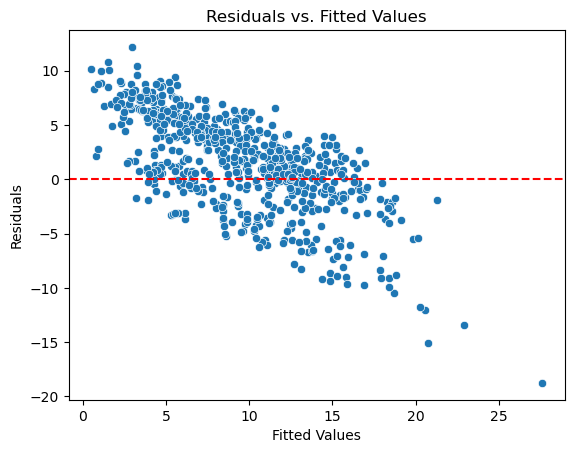

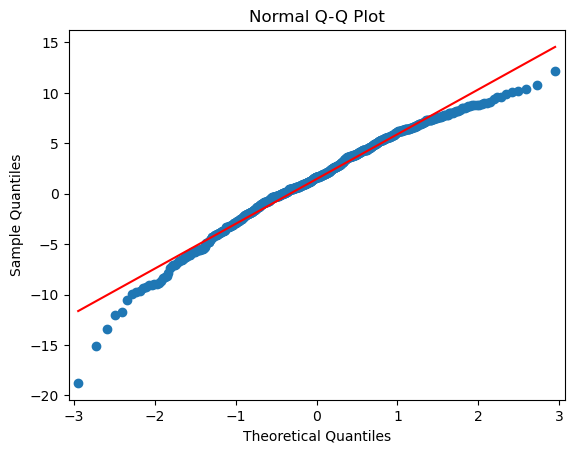

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
# Assuming 'model' is your fitted regression model
# removed from model '8-tier employment entropy (denominator set to the static 8 employment types in the CBG)'
# X = df1[['Employment and household entropy', 'Households (occupied housing units), 2018']]
# y = df1['walkabilty_index']

X = df1[['Employment and household entropy', 'Households (occupied housing units), 2018']]
y = df1['walkabilty_index']




# # fit a residual plot
model = sm.OLS(y, X.astype(float)).fit()
residuals = model.resid
fitted_values = model.fittedvalues


sns.scatterplot(x=fitted_values, y=residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residuals vs. Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

import statsmodels.api as sm
import matplotlib.pyplot as plt

# Assuming 'model' is your fitted regression model
residuals = model.resid

# Plotting
sm.qqplot(residuals, line='s')
plt.title("Normal Q-Q Plot")
plt.show()

In [75]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)
# X = df1[['Households (occupied housing units), 2018', '8-tier employment entropy (denominator set to the static 8 employment types in the CBG)', 'Employment and household entropy']]
# y = df1["walkabilty_index"]
X = 
# df1[['Employment and household entropy', 'Households (occupied housing units), 2018']]
y = df1['walkabilty_index']
# Convert to DataFrame for better visualization
df = pd.DataFrame({"X": X.squeeze(), "y": y})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train the model
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)

# Predict
y_pred = rf_reg.predict(X_test)

# Calculate performance metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Random Forest Regression Coefficients:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared: {r2:.4f}")

# Feature Importances
feature_importances = rf_reg.feature_importances_
print("Feature Importances:")
for idx, importance in enumerate(feature_importances):
    print(f"Feature {idx + 1}: {importance:.4f}")

# Visualization of Feature Importance
plt.figure(figsize=(8, 5))
plt.bar(range(len(feature_importances)), feature_importances, color='skyblue')
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Feature Importance in Random Forest Regression")
plt.show()

ValueError: Data must be 1-dimensional, got ndarray of shape (628, 2) instead

In [19]:
df2 = pd.read_csv("mpd_pub_saf.csv")

df2.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 657812 entries, 0 to 657811
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Crime ID              657812 non-null  object 
 1   Offense Datetime      657730 non-null  object 
 2   Reported Datetime     657738 non-null  object 
 3   Agency Crime ID       657811 non-null  object 
 4   UCR Incident Code     657812 non-null  object 
 5   Block                 657812 non-null  int64  
 6   Street Name           657802 non-null  object 
 7   Street_Address        657812 non-null  object 
 8   City                  657616 non-null  object 
 9   State                 657812 non-null  object 
 10  ZIP Code              657615 non-null  object 
 11  Full_Address          657812 non-null  object 
 12  Latitude              657812 non-null  float64
 13  Longitude             657812 non-null  float64
 14  UCR Category          657811 non-null  object 
 15  